<a href="https://colab.research.google.com/github/muhammadbinasim33-ui/Jupiter-notebooks/blob/main/Bass_Model_replicated_on_SmartPhones_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. Import Libraries**



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
print ("Libraries imported")


Libraries imported


## **2. Data Load**

In [ ]:
smart = pd.read_csv("/content/drive/MyDrive/global_smartphone_shipments_2011_2023.csv")
s = smart[(smart.year >=2012)& (smart.year<=2017)].copy()
s["Y2"] = s["Y_t_minus_1"]**2
X = sm.add_constant(s[["Y_t_minus_1", "Y2"]])   # columns: const, Y, Y²
model = sm.OLS(s["shipments_millions"], X).fit()

print(model.summary())   # coefficients, t-ratios, R²
a, b, c = model.params   # const = a, Y_t_minus_1 = b, Y2 = c

                            OLS Regression Results                            
Dep. Variable:     shipments_millions   R-squared:                       0.978
Model:                            OLS   Adj. R-squared:                  0.963
Method:                 Least Squares   F-statistic:                     65.98
Date:                Tue, 06 Oct 2026   Prob (F-statistic):            0.00331
Time:                        10:28:38   Log-Likelihood:                -31.188
No. Observations:                   6   AIC:                             68.38
Df Residuals:                       3   BIC:                             67.75
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         610.6586     71.658      8.522      

/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


### PEAK CHECK

In [ ]:
m = (-b - np.sqrt(b**2 - 4*a*c)) / (2*c)
p = a / m
q = -m * c

T_star = np.log(q/p) / (p + q)          # predicted peak time (periods)
S_peak = m * (p + q)**2 / (4*q)         # predicted peak sales (millions)
Y_peak = m * (q - p) / (2*q)            # cumulative sales at the peak

print(f"m = {m:.1f}, p = {p:.4f}, q = {q:.4f}, q/p = {q/p:.1f}")
print(f"T* = {T_star:.2f}, S(T*) = {S_peak:.1f}, Y(T*) = {Y_peak:.1f}")

# actual peak
actual = smart[(smart.year >= 2012) & (smart.year <= 2017)]
peak_row = actual.loc[actual.shipments_millions.idxmax()]
actual_T = peak_row.year - 2012 + 1     # period 1 = 2012
print("Actual peak:", int(peak_row.year), "period", int(actual_T),
      "sales", peak_row.shipments_millions)

m = 12290.8, p = 0.0497, q = 0.4095, q/p = 8.2
T* = 4.59, S(T*) = 1582.1, Y(T*) = 5399.8
Actual peak: 2017 period 6 sales 1566


### 2nd Window: 2012-2019

In [ ]:
s1 = smart[(smart.year >=2012)& (smart.year<=2019)].copy()
s1["Y2"] = s1["Y_t_minus_1"]**2
X = sm.add_constant(s1[["Y_t_minus_1", "Y2"]])   # columns: const, Y, Y²
model = sm.OLS(s1["shipments_millions"], X).fit()

print(model.summary())   # coefficients, t-ratios, R²
a, b, c = model.params   # const = a, Y_t_minus_1 = b, Y2 = c

                            OLS Regression Results                            
Dep. Variable:     shipments_millions   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.925
Method:                 Least Squares   F-statistic:                     44.20
Date:                Tue, 06 Oct 2026   Prob (F-statistic):           0.000663
Time:                        10:28:57   Log-Likelihood:                -44.460
No. Observations:                   8   AIC:                             94.92
Df Residuals:                       5   BIC:                             95.16
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         699.5320     74.911      9.338      

## PEAK OF 2nd Window:

In [ ]:
m = (-b - np.sqrt(b**2 - 4*a*c)) / (2*c)
p = a / m
q = -m * c

T_star = np.log(q/p) / (p + q)          # predicted peak time (periods)
S_peak = m * (p + q)**2 / (4*q)         # predicted peak sales (millions)
Y_peak = m * (q - p) / (2*q)            # cumulative sales at the peak

print(f"m = {m:.1f}, p = {p:.4f}, q = {q:.4f}, q/p = {q/p:.1f}")
print(f"T* = {T_star:.2f}, S(T*) = {S_peak:.1f}, Y(T*) = {Y_peak:.1f}")

# actual peak
actual = smart[(smart.year >= 2012) & (smart.year <= 2019)]
peak_row = actual.loc[actual.shipments_millions.idxmax()]
actual_T = peak_row.year - 2012 + 1     # period 1 = 2012
print("Actual peak:", int(peak_row.year), "period", int(actual_T),
      "sales", peak_row.shipments_millions)

m = 15496.8, p = 0.0451, q = 0.3186, q/p = 7.1
T* = 5.37, S(T*) = 1608.7, Y(T*) = 6650.4
Actual peak: 2017 period 6 sales 1566


## **Forecasting of Both Windows:**

    year  actual  forecast_2012-2017  err%_2012-2017  forecast_2012-2019  \
0   2012     741               610.7           -17.6               699.5   
1   2013    1049               855.3           -18.5               905.1   
2   2014    1318              1131.3           -14.2              1128.3   
3   2015    1462              1387.9            -5.1              1342.8   
4   2016    1519              1553.1             2.2              1512.5   
5   2017    1566              1568.4             0.2              1601.3   
6   2018    1505              1428.0            -5.1              1587.9   
7   2019    1479              1182.8           -20.0              1475.7   
8   2020    1331               905.6           -32.0              1290.9   
9   2021    1391               652.7           -53.1              1071.1   
10  2022    1225               450.2           -63.2               850.4   
11  2023    1171               301.3           -74.3               651.9   

    err%_20

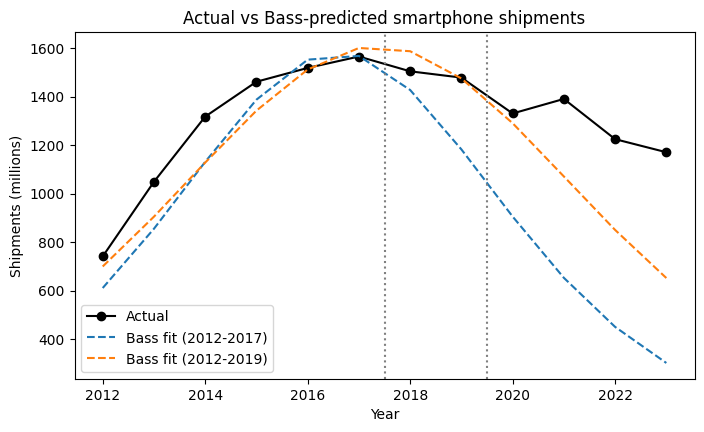

In [ ]:
def bass_S(T, m, p, q):
    e = np.exp(-(p+q)*T)
    return m * (p+q)**2 / p * e / ((q/p)*e + 1)**2

def fit_params(df, start, end):
    d = df[(df.year >= start) & (df.year <= end)].copy()
    d["Y2"] = d["Y_t_minus_1"]**2
    res = sm.OLS(d["shipments_millions"],
                 sm.add_constant(d[["Y_t_minus_1", "Y2"]])).fit()
    a, b, c = res.params
    m = (-b - np.sqrt(b**2 - 4*a*c)) / (2*c)
    return m, a/m, -m*c

years_all = np.arange(2012, 2024)
T_all = years_all - 2012            # period 1 -> T = 0
actual_all = smart.set_index("year").loc[years_all, "shipments_millions"]

out = pd.DataFrame({"year": years_all, "actual": actual_all.values})
windows = {"2012-2017": (2012, 2017), "2012-2019": (2012, 2019)}

for name, (s, e) in windows.items():
    m, p, q = fit_params(smart, s, e)
    out[f"forecast_{name}"] = bass_S(T_all, m, p, q)
    out[f"err%_{name}"] = 100*(out[f"forecast_{name}"] - out.actual)/out.actual

print(out.round(1))

# r² inside each window
for name, (s, e) in windows.items():
    mask = (out.year >= s) & (out.year <= e)
    r2 = np.corrcoef(out.actual[mask], out[f"forecast_{name}"][mask])[0,1]**2
    print(name, "in-window r²:", round(r2, 3))

# plot
plt.figure(figsize=(8,4.5))
plt.plot(out.year, out.actual, "k-o", label="Actual")
plt.plot(out.year, out["forecast_2012-2017"], "--", label="Bass fit (2012-2017)")
plt.plot(out.year, out["forecast_2012-2019"], "--", label="Bass fit (2012-2019)")
plt.axvline(2017.5, color="gray", ls=":"); plt.axvline(2019.5, color="gray", ls=":")
plt.xlabel("Year"); plt.ylabel("Shipments (millions)")
plt.title("Actual vs Bass-predicted smartphone shipments")
plt.legend(); plt.show()